# CART-derived Hessian vs. residual-based PHD on OPFData IEEE-118 — 3D

**Research question.** On a real regression dataset (operating cost as a function of 3 bus demands), how does the
Hessian reconstructed from an ordinary CART tree by the effective-centre method compare with the classical
residual-based principal Hessian directions (PHD) estimate, and is the raw CART reconstruction internally
consistent (symmetric) when its rows are solved independently?

**What this notebook does not claim.** Neither estimate is a true Hessian. The CSV provides no reference
derivative. PHD is a baseline with its own assumption (a Gaussian predictor design); agreement or disagreement
with it is reported, not scored.

**Data and column convention.** Headerless CSV `118_ieee_smol.csv`, 5,000 rows × 100 columns.
Column 0 is the response (operating cost of the solved optimal power flow). Columns 1, 2, 3 are the predictors and
are labelled *Load 1..3* below (Load k ≡ CSV column k). Columns 1–99 are consistent with per-unit active demand at
the 99 load elements of the IEEE-118 case: their means sum to 42.40 p.u. (4,240 MW against the case's nominal
4,242 MW). Physical bus identities per column are not established here. Only the first 4 columns are read;
the file is not modified and the full 2 GB dataset is not used.

**Approach.**
1. Fit an ordinary sklearn CART regression tree (squared-error criterion). Two settings are reported:
   **A** `max_depth=7, min_samples_leaf=1` (sklearn default leaf size) and **B** `max_depth=7, min_samples_leaf=50`.
2. From each internal node take the two child-node response means and form the first-derivative estimate
   γ = 2(μ_right − μ_left)/(hi_s − lo_s) along the split axis s.
3. Reconstruct the Hessian with **Algorithm 1 of the manuscript, implemented line by line** (`hessian_tools.
   algorithm1_hessian`): for every internal node compute γ by eq. (3) and the effective location z by eq. (4),
   z_s = (lo_s + τ + hi_s)/3 and z_p = (lo_p + hi_p)/2 for p ≠ s; for every ordered pair of distinct nodes with the
   same split axis and z_A ≠ z_B append (z_B − z_A)ᵀ to V_s and γ_B − γ_A to y_s; for each s check rank(V_s) = d
   (else "not identified") and solve by least squares for row s of Q̃; return Q̂ = (Q̃ + Q̃ᵀ)/2. The matrix **before**
   line 19, Q̃, is reported first because its off-diagonal pairs are two independent estimates of one quantity.
4. Implement residual-based PHD independently (conventions stated in §5).
5. Print both matrices, check the raw CART matrix for symmetry pair by pair, then compare with PHD.
6. Controlled check: apply the same reconstruction, on the same fitted partition, to a quadratic with a known
   Hessian, to attribute any inconsistency to code, geometry, cell size, or the within-cell distribution of the
   real predictors.

## The method in plain terms (3D)

We have three inputs (Load 1, Load 2, Load 3) and one output, the cost. We want six numbers: the three curvatures Q₁₁, Q₂₂, Q₃₃ and the three interactions Q₁₂, Q₁₃, Q₂₃.

**Step 1 — one slope per split.** Take an internal node that splits on Load 1: a box with a cut at τ, left-child mean
cost μ_L, right-child mean cost μ_R. Then γ = (μ_R − μ_L) / ((hi₁ − lo₁)/2) is a slope of cost with respect to
Load 1 — the two child boxes' centres are half the box width apart along Load 1, so this is "rise over run". A
Load-2 split gives a slope with respect to Load 2 the same way, and a Load-3 split with respect to Load 3.

**Step 2 — where that slope is measured.** The slope is not "at the cut". For a quadratic cost it equals the derivative
at one point in the box: along the split axis, (lo + τ + hi)/3, the average of the three breakpoints; along every other
axis, the middle of the box. Call that point z. Each split now reads: *"the Load-s slope at location z is γ."*

**Step 3 — two slopes make one equation.** Take two Load-1 splits, A and B. If the cost is quadratic, the Load-1 slope
changes linearly as you move, so

    γ_B − γ_A = Q₁₁·(z_B,1 − z_A,1) + Q₁₂·(z_B,2 − z_A,2) + Q₁₃·(z_B,3 − z_A,3)

Read it as: the slope changed because we moved along Load 1 (curvature Q₁₁ acts) and along the other axes
(interactions act). Two special cases: if A and B sit at the same height in the other axes, only Q₁₁ remains — "the
slope changed as I moved along Load 1"; if they sit at the same Load-1 position but different heights, only the
interaction terms remain — "the Load-1 slope changed as I moved in Load 2": that *is* an interaction.

**Step 4 — many equations, solve.** Every pair of Load-1 splits gives one equation in (Q₁₁, Q₁₂, Q₁₃). Stack them and solve
by least squares → row 1 of the Hessian. Repeat with Load-2 splits for row 2 and Load-3 splits for row 3.
The pairs must spread in every direction, otherwise the equations cannot separate the unknowns — that is the rank check.

**Step 5 — the symmetry check.** Row 1 gives Q₁₂ from Load-1 splits; row 2 gives Q₂₁ from Load-2 splits. A true Hessian
has Q₁₂ = Q₂₁, and the two were computed from completely different splits, so their gap measures the method's error
without needing any truth. Algorithm 1's last line averages them; this notebook looks at them *before* averaging.
In 3D there are three such pairs to check: (1,2), (1,3), (2,3).

**Why this can fail on real data.** Step 2 assumes rows fill each box evenly — that is where the /3 and the box-middle
come from. If they do not, z is mislocated and the Step-3 equations are built on the wrong coordinates. And each μ is
an average over the rows in a child, so it is noisy; the method differences these averages twice.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import hessian_tools as L
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) < 1e3 else f"{v:,.2f}")
display(L.software_versions())

,version
python,3.13.18
numpy,2.5.3
pandas,3.0.5
scikit-learn,1.9.1
matplotlib,3.11.2
platform,Linux-6.18.44-fc-v310-x86_64-with-glibc2.39


## 1. Inputs

In [2]:
D = 3
X, y, csv_path = L.load_opf(D)
print("file:", csv_path)
print("X shape:", X.shape, "| y shape:", y.shape)
display(L.describe_inputs(X, y))
print("predictor correlation matrix:")
display(L.matrix_frame(np.corrcoef(X.T), "corr"))

file: /mnt/user-data/uploads/118_ieee_smol.csv
X shape: (5000, 3) | y shape: (5000,)


,count,mean,std,min,max
cost (col 0),5000,"93,757.84","13,560.62","69,269.90","124,285.53"
Load 1 (col 1),5000,0.5104,0.0833,0.3294,0.7332
Load 2 (col 2),5000,0.2001,0.0323,0.1297,0.2868
Load 3 (col 3),5000,0.3904,0.0644,0.2536,0.5568


predictor correlation matrix:


,Load 1,Load 2,Load 3
corr,,,
Load 1,1.0000,0.4731,0.4866
Load 2,0.4731,1.0000,0.4905
Load 3,0.4866,0.4905,1.0000


## 2. CART fit and first-derivative extraction

The tree is fitted to the raw (unscaled) data. The table lists every internal node with its split axis, extent along
that axis, threshold τ, the two child-node response means, the eq.-3 gradient estimate γ and the effective centre c.
The root box is the observed data range per axis.

In [3]:
settings = {"A": dict(max_depth=7, min_samples_leaf=1), "B": dict(max_depth=7, min_samples_leaf=50)}
trees, nodes, splits = {}, {}, {}
for k, kw in settings.items():
    trees[k] = L.fit_cart(X, y, **kw)
    nodes[k] = L.nodes_from_cart(trees[k], X)
    splits[k] = L.split_table(nodes[k])
    print(f"setting {k}: {kw} -> {len(splits[k])} internal nodes, "
          f"{int(trees[k].get_n_leaves())} leaves; "
          + ", ".join(f"{s}: {(splits[k]['split axis']==s).sum()}" for s in sorted(splits[k]['split axis'].unique())))
print("\nsetting B, first rows of the split table:")
display(splits["B"].head(12))

setting A: {'max_depth': 7, 'min_samples_leaf': 1} -> 124 internal nodes, 125 leaves; Load 1: 44, Load 2: 41, Load 3: 39
setting B: {'max_depth': 7, 'min_samples_leaf': 50} -> 46 internal nodes, 47 leaves; Load 1: 15, Load 2: 16, Load 3: 15

setting B, first rows of the split table:


,node,depth,split axis,lo_s,tau,hi_s,n,n_left,n_right,mean_left,mean_right,gamma (eq. 3),c_1,c_2,c_3
0,52,1,Load 1,0.3294,0.4655,0.7332,2289,360,1929,"90,869.45","104,515.59","67,585.08",0.5094,0.2083,0.4743
1,2,2,Load 1,0.3294,0.5466,0.7332,2141,1875,266,"81,288.95","96,063.75","73,174.97",0.5364,0.1708,0.3227
2,3,3,Load 1,0.3294,0.4437,0.5466,1875,859,1016,"78,426.23","83,709.31","48,651.53",0.4399,0.1708,0.3227
3,30,3,Load 1,0.5466,0.5955,0.7332,266,180,86,"92,751.41","102,996.57","109,784.78",0.6251,0.1708,0.3227
4,54,3,Load 1,0.3294,0.4153,0.4655,218,77,141,"83,372.59","89,903.19","95,987.54",0.4034,0.2083,0.4095
5,59,3,Load 1,0.3294,0.4402,0.4655,142,58,84,"92,404.02","98,303.93","86,717.48",0.4117,0.2083,0.4921
6,4,4,Load 1,0.3294,0.3797,0.4437,859,238,621,"75,057.85","79,717.17","81,528.73",0.3843,0.1708,0.3227
7,39,4,Load 1,0.3294,0.5296,0.7332,152,91,61,"89,400.73","94,381.84","24,669.88",0.5307,0.2209,0.3025
8,44,4,Load 1,0.3294,0.5552,0.7332,202,133,69,"97,055.35","103,927.46","34,035.41",0.5393,0.2230,0.3716
9,71,4,Load 1,0.4655,0.6369,0.7332,1324,1102,222,"103,082.22","111,774.53","64,928.72",0.6119,0.2359,0.4432


## 3. Algorithm 1: Q̃ before symmetrisation (line 19 not yet applied)

Rank diagnostics per row s: number of nodes splitting axis s, number of rows in V_s (ordered pairs, so twice the
number of unordered pairs), rank of V_s (must equal 3, else Algorithm 1 returns "not identified"), and its
condition number.

Two cross-checks confirm the implementation: the Week 45 solver (unordered pairs, same equations) and the
centred-regression formulation used in cedar_baseline must both reproduce Q̃ to rounding.

In [4]:
H_raw, H_hat, diag = {}, {}, {}
for k in settings:
    res = L.algorithm1_hessian(nodes[k], D)
    H_raw[k], H_hat[k], diag[k] = res["Q_tilde"], res["Q_hat"], res["diag"]
    w45, _ = L.cart_hessian_raw(nodes[k], D)
    alt = L.centred_regression_rows(nodes[k], D)
    print(f"--- setting {k}: identified = {res['identified']} ---")
    display(diag[k])
    print("Q_tilde (Algorithm 1 before line 19, NOT symmetrised):")
    display(L.matrix_frame(H_raw[k], f"Q_tilde {k}"))
    print(f"max |Algorithm 1 - Week 45 solver| = {np.nanmax(np.abs(H_raw[k]-w45)):.2e} | "
          f"max |Algorithm 1 - centred regression| = {np.nanmax(np.abs(H_raw[k]-alt)):.2e}\n")

--- setting A: identified = True ---


,row,n_nodes,n_rows_V,rank,cond
0,Load 1,44,1892,3,3.0312
1,Load 2,41,1640,3,2.5135
2,Load 3,39,1482,3,2.9854


Q_tilde (Algorithm 1 before line 19, NOT symmetrised):


,Load 1,Load 2,Load 3
Q_tilde A,,,
Load 1,"-399,605.64","1,153,309.03","1,158,807.55"
Load 2,"-1,022,674.04","-1,601,111.01","120,826.50"
Load 3,"777,750.47","-2,121,290.08","315,482.40"


max |Algorithm 1 - Week 45 solver| = 4.66e-10 | max |Algorithm 1 - centred regression| = 9.31e-10

--- setting B: identified = True ---


,row,n_nodes,n_rows_V,rank,cond
0,Load 1,15,210,3,4.8786
1,Load 2,16,240,3,2.5943
2,Load 3,15,210,3,4.8326


Q_tilde (Algorithm 1 before line 19, NOT symmetrised):


,Load 1,Load 2,Load 3
Q_tilde B,,,
Load 1,"4,871.58","-532,966.98","172,598.44"
Load 2,"593,212.41","-561,129.57","-175,082.93"
Load 3,"-108,303.21","589,938.14","62,409.90"


max |Algorithm 1 - Week 45 solver| = 2.33e-10 | max |Algorithm 1 - centred regression| = 4.07e-10



## 4. Independent residual-based PHD

Conventions: predictors centred by their sample mean; Σ = XcᵀXc / n (divisor n); residual r from the ordinary
least-squares fit of the cost on an intercept and the linear predictor terms; M = Σᵢ rᵢ xcᵢ xcᵢᵀ / n; estimate
H_PHD = Σ⁻¹ M Σ⁻¹, in the original units of cost per (predictor unit)². M is symmetric by construction, so the
reported asymmetry of H_PHD is at rounding level and is shown only for completeness.

In [5]:
H_phd, cond_sigma, asym_phd = L.phd_residual(X, y)
print(f"condition number of Sigma: {cond_sigma:.2f} | Frobenius asymmetry of H_PHD: {asym_phd:.1e}")
display(L.matrix_frame(H_phd, "PHD"))

condition number of Sigma: 12.89 | Frobenius asymmetry of H_PHD: 7.8e-17


,Load 1,Load 2,Load 3
PHD,,,
Load 1,"152,100.92","-232,667.53","-106,877.38"
Load 2,"-232,667.53","956,292.50","-353,929.23"
Load 3,"-106,877.38","-353,929.23","249,668.28"


## 5. Both estimates side by side (original units)

In [6]:
for k in settings:
    print(f"Algorithm 1 Q_tilde (before line 19), setting {k}:"); display(L.matrix_frame(H_raw[k], f"Q_tilde {k}"))
    print(f"Algorithm 1 Q_hat (line 19 output), setting {k}:"); display(L.matrix_frame(H_hat[k], f"Q_hat {k}"))
print("PHD:"); display(L.matrix_frame(H_phd, "PHD"))

Algorithm 1 Q_tilde (before line 19), setting A:


,Load 1,Load 2,Load 3
Q_tilde A,,,
Load 1,"-399,605.64","1,153,309.03","1,158,807.55"
Load 2,"-1,022,674.04","-1,601,111.01","120,826.50"
Load 3,"777,750.47","-2,121,290.08","315,482.40"


Algorithm 1 Q_hat (line 19 output), setting A:


,Load 1,Load 2,Load 3
Q_hat A,,,
Load 1,"-399,605.64","65,317.49","968,279.01"
Load 2,"65,317.49","-1,601,111.01","-1,000,231.79"
Load 3,"968,279.01","-1,000,231.79","315,482.40"


Algorithm 1 Q_tilde (before line 19), setting B:


,Load 1,Load 2,Load 3
Q_tilde B,,,
Load 1,"4,871.58","-532,966.98","172,598.44"
Load 2,"593,212.41","-561,129.57","-175,082.93"
Load 3,"-108,303.21","589,938.14","62,409.90"


Algorithm 1 Q_hat (line 19 output), setting B:


,Load 1,Load 2,Load 3
Q_hat B,,,
Load 1,"4,871.58","30,122.71","32,147.62"
Load 2,"30,122.71","-561,129.57","207,427.61"
Load 3,"32,147.62","207,427.61","62,409.90"


PHD:


,Load 1,Load 2,Load 3
PHD,,,
Load 1,"152,100.92","-232,667.53","-106,877.38"
Load 2,"-232,667.53","956,292.50","-353,929.23"
Load 3,"-106,877.38","-353,929.23","249,668.28"


## 6. Symmetry of Q̃ (what line 19 averages away)

A 3×3 matrix has 3 distinct off-diagonal pairs
((1,2), (1,3), (2,3)). For each pair the table shows H[i,j]
(from the row solved with axis-i nodes), H[j,i] (from axis-j nodes), the signed gap, the absolute gap, and the gap
relative to the larger of the two entries. The summary gives mean, median and maximum absolute gap over the three pairs.
Nothing is symmetrised in this section.

In [7]:
for k in settings:
    pairs, summary = L.symmetry_pairs(H_raw[k])
    print(f"--- setting {k} ---"); display(pairs); display(summary)

--- setting A ---


,"pair (i,j)","H[i,j]","H[j,i]","signed gap H[i,j]-H[j,i]",abs gap,"abs gap / max(|H[i,j]|,|H[j,i]|)"
0,"(1,2)","1,153,309.03","-1,022,674.04","2,175,983.07","2,175,983.07",1.8867
1,"(1,3)","1,158,807.55","777,750.47","381,057.08","381,057.08",0.3288
2,"(2,3)","120,826.50","-2,121,290.08","2,242,116.58","2,242,116.58",1.0570


,distinct pairs,mean abs gap,median abs gap,max abs gap
0,3,"1,599,718.91","2,175,983.07","2,242,116.58"


--- setting B ---


,"pair (i,j)","H[i,j]","H[j,i]","signed gap H[i,j]-H[j,i]",abs gap,"abs gap / max(|H[i,j]|,|H[j,i]|)"
0,"(1,2)","-532,966.98","593,212.41","-1,126,179.39","1,126,179.39",1.8984
1,"(1,3)","172,598.44","-108,303.21","280,901.65","280,901.65",1.6275
2,"(2,3)","-175,082.93","589,938.14","-765,021.07","765,021.07",1.2968


,distinct pairs,mean abs gap,median abs gap,max abs gap
0,3,"724,034.04","765,021.07","1,126,179.39"


## 7. Comparison with PHD

First Q̃ against PHD, entry by entry. Then the Algorithm 1 output Q̂ = (Q̃ + Q̃ᵀ)/2 against PHD — reported only after
the discrepancies above, so that line 19 is a visible step and not a hidden one. Differences are between two
estimates; no column is a truth value.

In [8]:
for k in settings:
    print(f"--- setting {k}: Q_tilde vs PHD ---")
    display(L.comparison_table(H_raw[k], H_phd, f"Q_tilde {k}"))
    asym = np.linalg.norm(H_raw[k] - H_raw[k].T) / np.linalg.norm(H_raw[k])
    print(f"--- setting {k}: Q_hat (Algorithm 1 output) vs PHD   (asymmetry of Q_tilde ||Q-Qᵀ||/||Q|| = {asym:.3f}) ---")
    display(L.comparison_table(H_hat[k], H_phd, f"Q_hat {k}"))

--- setting A: Q_tilde vs PHD ---


,entry,Q_tilde A,PHD,CART - PHD,|CART - PHD|
0,"(1,1)","-399,605.64","152,100.92","-551,706.56","551,706.56"
1,"(1,2)","1,153,309.03","-232,667.53","1,385,976.56","1,385,976.56"
2,"(1,3)","1,158,807.55","-106,877.38","1,265,684.93","1,265,684.93"
3,"(2,1)","-1,022,674.04","-232,667.53","-790,006.51","790,006.51"
4,"(2,2)","-1,601,111.01","956,292.50","-2,557,403.51","2,557,403.51"
5,"(2,3)","120,826.50","-353,929.23","474,755.73","474,755.73"
6,"(3,1)","777,750.47","-106,877.38","884,627.84","884,627.84"
7,"(3,2)","-2,121,290.08","-353,929.23","-1,767,360.84","1,767,360.84"
8,"(3,3)","315,482.40","249,668.28","65,814.12","65,814.12"


--- setting A: Q_hat (Algorithm 1 output) vs PHD   (asymmetry of Q_tilde ||Q-Qᵀ||/||Q|| = 1.304) ---


,entry,Q_hat A,PHD,CART - PHD,|CART - PHD|
0,"(1,1)","-399,605.64","152,100.92","-551,706.56","551,706.56"
1,"(1,2)","65,317.49","-232,667.53","297,985.02","297,985.02"
2,"(1,3)","968,279.01","-106,877.38","1,075,156.38","1,075,156.38"
3,"(2,1)","65,317.49","-232,667.53","297,985.02","297,985.02"
4,"(2,2)","-1,601,111.01","956,292.50","-2,557,403.51","2,557,403.51"
5,"(2,3)","-1,000,231.79","-353,929.23","-646,302.55","646,302.55"
6,"(3,1)","968,279.01","-106,877.38","1,075,156.38","1,075,156.38"
7,"(3,2)","-1,000,231.79","-353,929.23","-646,302.55","646,302.55"
8,"(3,3)","315,482.40","249,668.28","65,814.12","65,814.12"


--- setting B: Q_tilde vs PHD ---


,entry,Q_tilde B,PHD,CART - PHD,|CART - PHD|
0,"(1,1)","4,871.58","152,100.92","-147,229.35","147,229.35"
1,"(1,2)","-532,966.98","-232,667.53","-300,299.45","300,299.45"
2,"(1,3)","172,598.44","-106,877.38","279,475.82","279,475.82"
3,"(2,1)","593,212.41","-232,667.53","825,879.94","825,879.94"
4,"(2,2)","-561,129.57","956,292.50","-1,517,422.07","1,517,422.07"
5,"(2,3)","-175,082.93","-353,929.23","178,846.30","178,846.30"
6,"(3,1)","-108,303.21","-106,877.38","-1,425.84","1,425.84"
7,"(3,2)","589,938.14","-353,929.23","943,867.38","943,867.38"
8,"(3,3)","62,409.90","249,668.28","-187,258.38","187,258.38"


--- setting B: Q_hat (Algorithm 1 output) vs PHD   (asymmetry of Q_tilde ||Q-Qᵀ||/||Q|| = 1.677) ---


,entry,Q_hat B,PHD,CART - PHD,|CART - PHD|
0,"(1,1)","4,871.58","152,100.92","-147,229.35","147,229.35"
1,"(1,2)","30,122.71","-232,667.53","262,790.24","262,790.24"
2,"(1,3)","32,147.62","-106,877.38","139,024.99","139,024.99"
3,"(2,1)","30,122.71","-232,667.53","262,790.24","262,790.24"
4,"(2,2)","-561,129.57","956,292.50","-1,517,422.07","1,517,422.07"
5,"(2,3)","207,427.61","-353,929.23","561,356.84","561,356.84"
6,"(3,1)","32,147.62","-106,877.38","139,024.99","139,024.99"
7,"(3,2)","207,427.61","-353,929.23","561,356.84","561,356.84"
8,"(3,3)","62,409.90","249,668.28","-187,258.38","187,258.38"


### Heatmaps (entries in millions of original units)

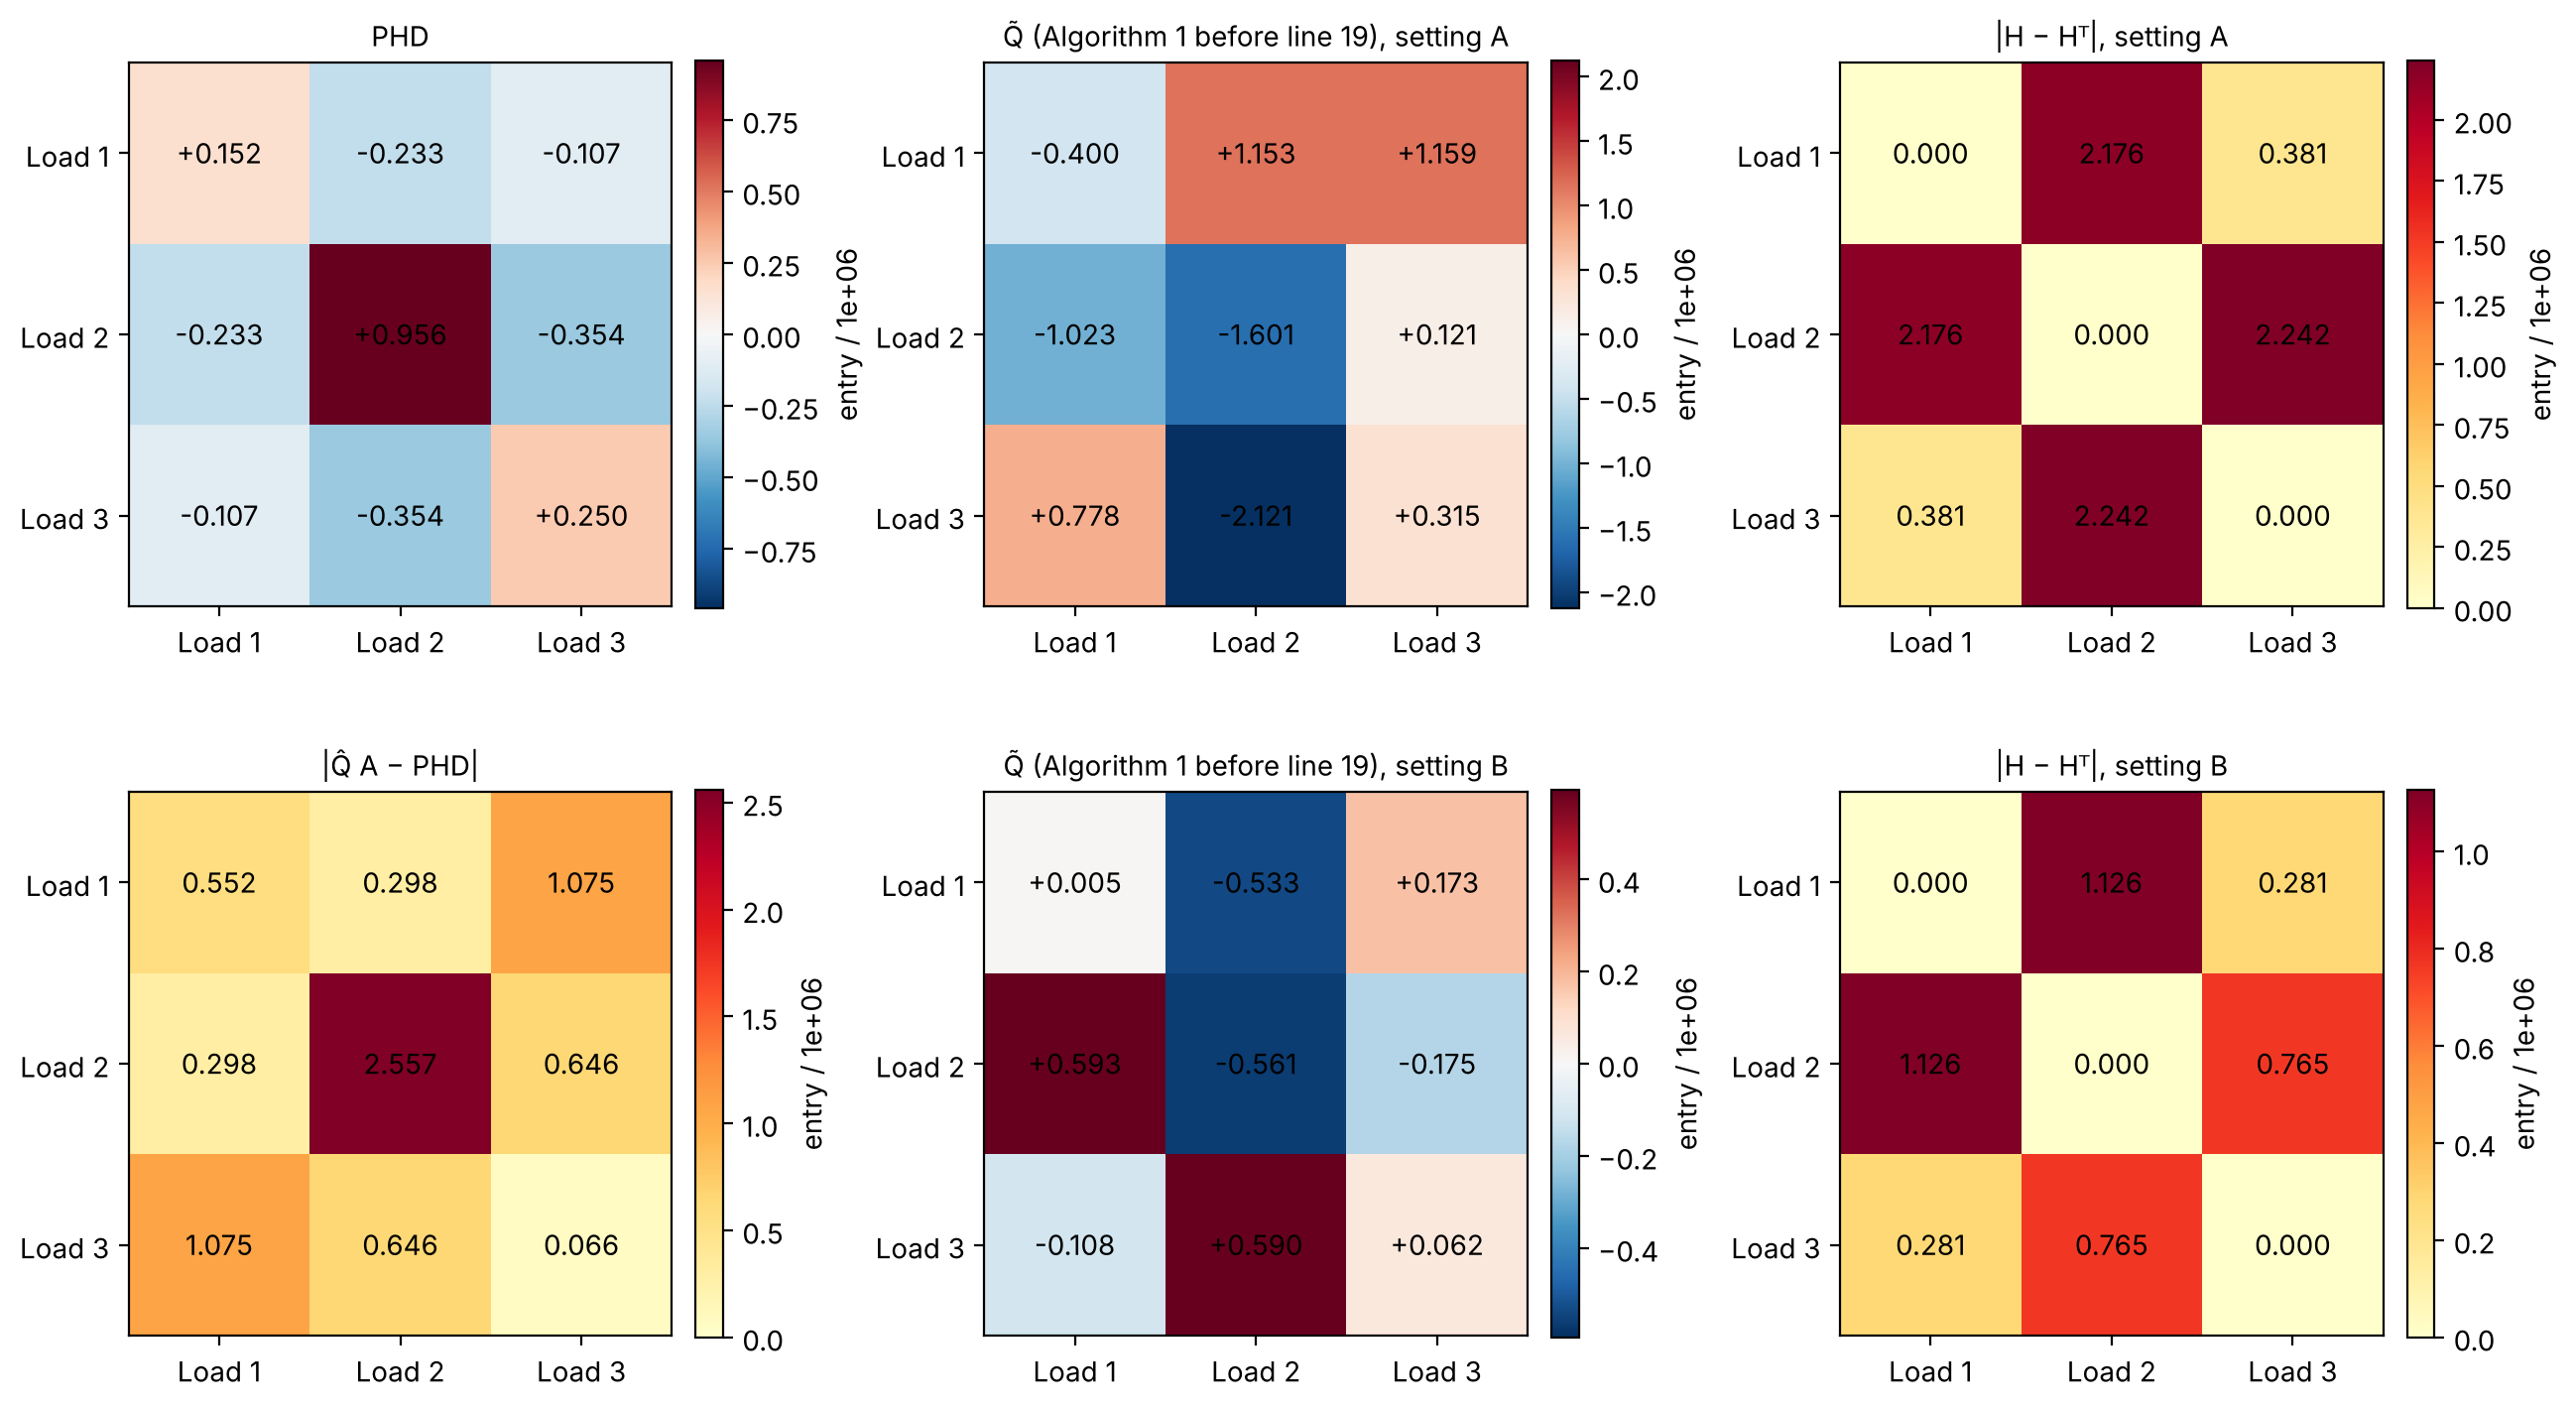

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
L.heatmap(H_phd, "PHD", axes[0, 0])
L.heatmap(H_raw["A"], "Q̃ (Algorithm 1 before line 19), setting A", axes[0, 1])
L.heatmap(np.abs(H_raw["A"] - H_raw["A"].T), "|H − Hᵀ|, setting A", axes[0, 2], absolute=True)
L.heatmap(np.abs(H_hat["A"] - H_phd), "|Q̂ A − PHD|", axes[1, 0], absolute=True)
L.heatmap(H_raw["B"], "Q̃ (Algorithm 1 before line 19), setting B", axes[1, 1])
L.heatmap(np.abs(H_raw["B"] - H_raw["B"].T), "|H − Hᵀ|, setting B", axes[1, 2], absolute=True)
fig.tight_layout(); plt.show()

## 8. Controlled check on the same partition: where does the inconsistency come from?

The reconstruction is exact for a quadratic when each node's value is the exact mean of that quadratic over the
node's box under the uniform measure. On the fitted partitions above, a quadratic with a known random symmetric
Hessian Q is evaluated three ways and reconstructed with the same solver:

- **(a) exact box means** — tests the geometry and the code only;
- **(b) sample means at the real rows** — the quadratic is evaluated at the OPFData predictor rows that fall in each
  box, no observation noise;
- **(c) uniform resample** — the same number of points per box as in (b), drawn uniformly on the box.

(a) separates code/geometry from everything else; (c) vs (a) measures the cost of finite cells; (b) vs (c) measures
the additional cost of the real rows being non-uniformly placed inside the boxes. Errors are max |Ĥ − Q| / max |Q|.
The last table reports, per internal node, how far the real rows' centroid sits from the box centroid relative to
the box width (0 under the uniform assumption).

In [10]:
rows = []
for k in settings:
    for seed in (0, 1, 2):
        c = L.known_quadratic_check(nodes[k], X, D, seed)
        scale = np.max(np.abs(c["Q_true"]))
        rows.append({"setting": k, "seed": seed,
                     "(a) exact box means": np.nanmax(np.abs(c["exact_box_means"] - c["Q_true"])) / scale,
                     "(b) real-row sample means": np.nanmax(np.abs(c["sample_means"] - c["Q_true"])) / scale,
                     "(c) uniform resample": np.nanmax(np.abs(c["uniform_resample"] - c["Q_true"])) / scale,
                     "ranks (a/b/c)": f"{c['rank_exact']}/{c['rank_sample']}/{c['rank_uniform']}"})
ctrl = pd.DataFrame(rows)
with pd.option_context("display.float_format", lambda v: f"{v:.2e}" if v < 1e-6 else f"{v:.2f}"):
    display(ctrl)
c = L.known_quadratic_check(nodes["B"], X, D, 0)
print("setting B, seed 0 — known Q:"); display(L.matrix_frame(c["Q_true"], "Q true"))
print("(a) exact box means:"); display(L.matrix_frame(c["exact_box_means"], "(a)"))
print("(b) real-row sample means:"); display(L.matrix_frame(c["sample_means"], "(b)"))
print("(c) uniform resample:"); display(L.matrix_frame(c["uniform_resample"], "(c)"))

,setting,seed,(a) exact box means,(b) real-row sample means,(c) uniform resample,ranks (a/b/c)
0,A,0,8.13e-14,7.13,27.01,"[3, 3, 3]/[3, 3, 3]/[3, 3, 3]"
1,A,1,1.25e-14,9.03,8.87,"[3, 3, 3]/[3, 3, 3]/[3, 3, 3]"
2,A,2,1.08e-14,10.02,14.74,"[3, 3, 3]/[3, 3, 3]/[3, 3, 3]"
3,B,0,1.45e-13,2.61,1.10,"[3, 3, 3]/[3, 3, 3]/[3, 3, 3]"
4,B,1,1.36e-14,3.70,1.42,"[3, 3, 3]/[3, 3, 3]/[3, 3, 3]"
5,B,2,8.14e-15,1.83,0.73,"[3, 3, 3]/[3, 3, 3]/[3, 3, 3]"


setting B, seed 0 — known Q:


,Load 1,Load 2,Load 3
Q true,,,
Load 1,0.1257,-0.0136,0.9722
Load 2,-0.0136,-0.5357,0.6543
Load 3,0.9722,0.6543,-0.7037


(a) exact box means:


,Load 1,Load 2,Load 3
(a),,,
Load 1,0.1257,-0.0136,0.9722
Load 2,-0.0136,-0.5357,0.6543
Load 3,0.9722,0.6543,-0.7037


(b) real-row sample means:


,Load 1,Load 2,Load 3
(b),,,
Load 1,0.3294,0.6038,0.3245
Load 2,-1.9593,-1.9758,2.2227
Load 3,1.5098,-1.8854,-0.1019


(c) uniform resample:


,Load 1,Load 2,Load 3
(c),,,
Load 1,0.1895,0.1530,0.9317
Load 2,-1.0392,-0.4529,1.7214
Load 3,0.5264,0.7598,-0.7155


In [11]:
u = L.within_cell_uniformity(nodes["B"], X)
print("setting B: |sample centroid − box centroid| / box width per axis; last row = mean over internal nodes")
display(u.tail(6))

setting B: |sample centroid − box centroid| / box width per axis; last row = mean over internal nodes


,node,depth,n,|offset|/width axis 1,|offset|/width axis 2,|offset|/width axis 3
41,10,5,621,0.0165,0.0292,0.0789
42,14,6,498,0.0267,0.0419,0.0942
43,11,6,123,0.0247,0.1224,0.0168
44,5,5,238,0.1140,0.0017,0.0064
45,7,6,188,0.0401,0.0060,0.0090
46,mean,,,0.0909,0.0897,0.1089


## 9. Findings

1. **The implementation is Algorithm 1.** `algorithm1_hessian` follows the pseudocode line by line; the Week 45
   solver and the centred-regression formulation reproduce its Q̃ to rounding (§3); rank is full in every row; and
   with exact box means the known quadratic is recovered to ~1e-14 on the fitted partitions (§8a). There is no
   coding defect in the reconstruction.
2. **Q̃ is not symmetric on this data**, by amounts comparable to or larger than the entries themselves (§6).
   Because row i and row j are estimated from disjoint sets of nodes, Q̃[i,j] and Q̃[j,i] are two independent
   estimates of the same quantity; their gap is a direct, assumption-free measure of estimation error. Line 19 of
   Algorithm 1 averages it away, so the published output Q̂ cannot show it; Q̃ must be inspected before line 19.
3. **Source of the inconsistency.** §8 shows that replacing exact box means by sample means of a *noise-free* known
   quadratic already produces errors of order 1–10× the true entries. With the same number of points per cell drawn
   uniformly on each box (c) the error is of the same order, so the dominant cause at n = 5,000 is sample-mean
   variability in small cells — second differences of noisy first differences. At setting B the real rows (b) give
   a larger error than the uniform resample (c) in every seed, so the non-uniform placement of the real predictor
   rows within boxes adds a further error (§8, last table: centroid offsets of roughly 7–11 % of the box width on
   average, against the 0 assumed by the effective-centre formula); at setting A the two effects are not separable.
   Larger leaves (setting B) reduce the inconsistency but do not remove it.
4. **Against PHD.** PHD gives a symmetric matrix with entries of order 10⁵–10⁶; the Algorithm 1 estimates disagree with it
   in magnitude and, for some entries, in sign (§7). Given (2)–(3), that disagreement cannot yet be attributed to
   either method's assumptions; it is within the CART estimate's own inconsistency.

## Limitations

- 5,000 rows is far below what second-difference estimation needs at depth 7; the full dataset was deliberately
  not used here.
- The effective-centre location assumes a uniform distribution within each box; the real predictors are correlated
  (§1) and non-uniform within boxes (§8). Equal weighting of all node pairs and pooling over the whole domain assume a
  globally quadratic response.
- PHD assumes a Gaussian predictor design, which the load perturbation scheme does not satisfy; it is a baseline,
  not a reference.
- Physical column identities beyond "cost" and "per-unit demand" are not verified.
- No eigenanalysis, bootstrap, prediction metric, or alternative estimator is included; those belong to later
  attempts after the above is resolved.